In [1]:
import numpy as np
import torch
from irl.swil import GSW
import matplotlib.pyplot as plt
import matplotlib

In [2]:
font_size = 24
matplotlib.rcParams['font.size'] = font_size
matplotlib.rcParams["font.weight"] = "bold"
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['axes.labelsize'] = font_size
matplotlib.rcParams['axes.titlesize'] = font_size
matplotlib.rcParams['legend.fontsize'] = font_size
matplotlib.rcParams['xtick.labelsize'] = font_size
matplotlib.rcParams['ytick.labelsize'] = font_size
matplotlib.rcParams['text.latex.preamble']=r'\usepackage{amsmath} \DeclareMathOperator{\F}{F} \DeclareMathOperator{\GMF}{GMF} \DeclareMathOperator{\MLP}{MLP}'

In [3]:
a = np.random.randn(100,4)
b = np.random.randn(100,4) + np.ones(4)*0

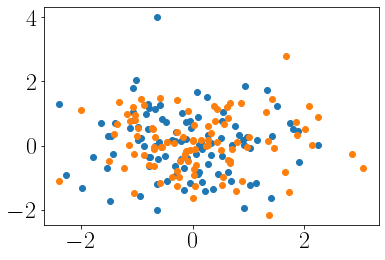

In [4]:
plt.scatter(a[:,0],a[:,1])
plt.scatter(b[:,0],b[:,1])

In [5]:
gsw = GSW(nofprojections=1)

In [6]:
a_s = gsw.get_slice(a,theta=None)[:20].numpy()
a_s_ = gsw.get_slice(a,theta=None)[:11].numpy()
b_s = gsw.get_slice(b,theta=None)[:20].numpy()

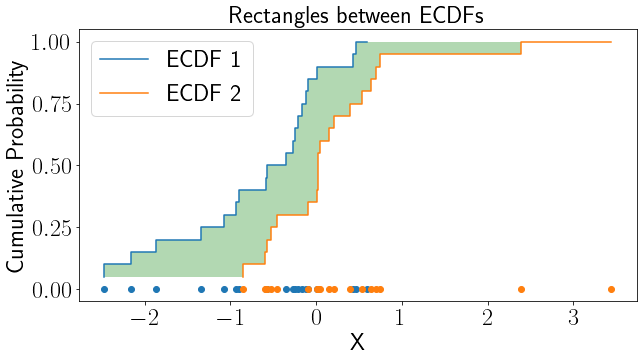

In [9]:
data1 = np.squeeze(a_s)
data1_ = np.squeeze(a_s_)
data2 = np.squeeze(b_s)

# Calculate the ECDFs
x1 = np.sort(data1)
x1_ = np.sort(data1_)
#x1[5]+=0.1
y1 = np.arange(1, len(data1) + 1) / len(data1)
y1_ = np.arange(1, len(data1_) + 1) / len(data1_)

x2 = np.sort(data2)
y2 = np.arange(1, len(data2) + 1) / len(data2)

# Calculate the rectangle coordinates
left = np.minimum(x1[:-1], x2[:-1])
right = np.maximum(x1[:-1], x2[:-1])
bottom = np.minimum(y1[:-1], y2[:-1])
height = np.abs(y1[1:] - y2[:-1])

# Create the figure and axes
fig, ax = plt.subplots(figsize=(10,5))

# Plot the ECDFsg
ax.scatter(x1, np.zeros_like(x1))
ax.scatter(x2, np.zeros_like(x2))
ax.step(x1, y1, label='ECDF 1')
ax.step(x2, y2, label='ECDF 2')

# Draw the rectangles
for l, r, b, h in zip(left, right, bottom, height):
    rect = plt.Rectangle((l, b), r - l, h, alpha=0.3, facecolor='green')
    ax.add_patch(rect)

# Add labels and legend
ax.set_xlabel('X')
ax.set_ylabel('Cumulative Probability')
ax.set_title('Rectangles between ECDFs')
ax.legend()

# Display the plot
#plt.show()
plt.savefig('cdfs.png')

torch.Size([10])


ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 1 dimension(s) and the array at index 1 has 0 dimension(s)